<a href="https://colab.research.google.com/github/Perpetuachinyere/skills-introduction-to-github/blob/main/INR_WALD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from google.colab import files
uploaded = files.upload()

Saving INR-WALD.xlsx to INR-WALD.xlsx


In [3]:
df = pd.read_excel('INR-WALD.xlsx')

In [4]:
df.head(10)

,DATE,INR
0,2003-12-01,45.710
1,2003-12-02,45.629
2,2003-12-03,45.550
3,2003-12-04,45.548
4,2003-12-05,45.449
5,2003-12-08,45.470
6,2003-12-09,45.431
7,2003-12-10,45.371
8,2003-12-11,45.449
9,2003-12-12,45.422


In [6]:
df.describe()

,DATE,INR
count,5361,5361.000000
mean,2014-03-24 08:25:14.941242368,59.564749
min,2003-12-01 00:00:00,39.045000
25%,2009-01-30 00:00:00,45.710000
50%,2014-03-27 00:00:00,61.380000
75%,2019-05-20 00:00:00,71.157300
max,2024-07-09 00:00:00,85.194000
std,NaN,13.597220


In [7]:
df['DATE'] = pd.to_datetime(df['DATE'])
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5361 entries, 0 to 5360
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   DATE    5361 non-null   datetime64[ns]
 1   INR     5361 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 83.9 KB


None

In [9]:
df.describe()

,DATE,INR
count,5361,5361.000000
mean,2014-03-24 08:25:14.941242368,59.564749
min,2003-12-01 00:00:00,39.045000
25%,2009-01-30 00:00:00,45.710000
50%,2014-03-27 00:00:00,61.380000
75%,2019-05-20 00:00:00,71.157300
max,2024-07-09 00:00:00,85.194000
std,NaN,13.597220


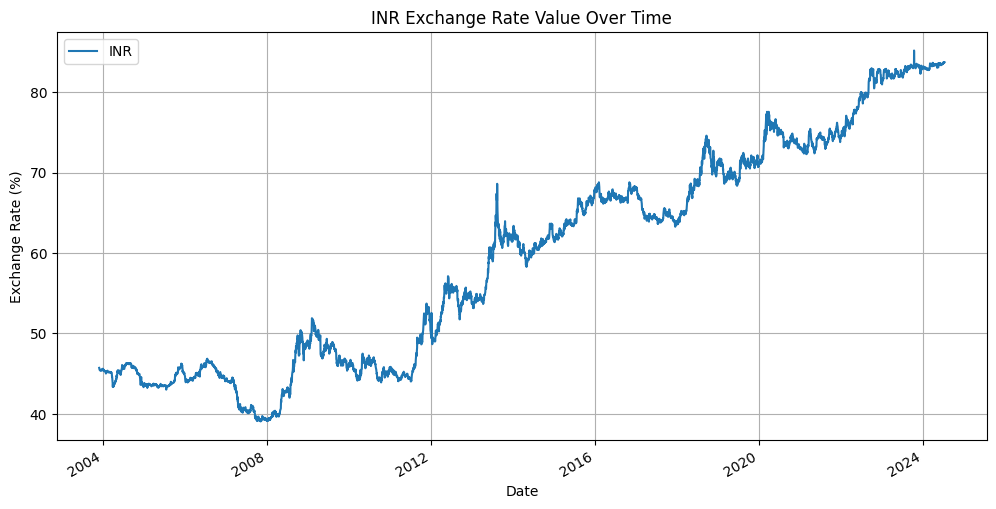

In [10]:
import matplotlib.pyplot as plt

df.plot(x='DATE', y='INR', figsize=(12, 6))
plt.title('INR Exchange Rate Value Over Time')
plt.xlabel('Date')
plt.ylabel('Exchange Rate (%)')
plt.grid(True)
plt.show()

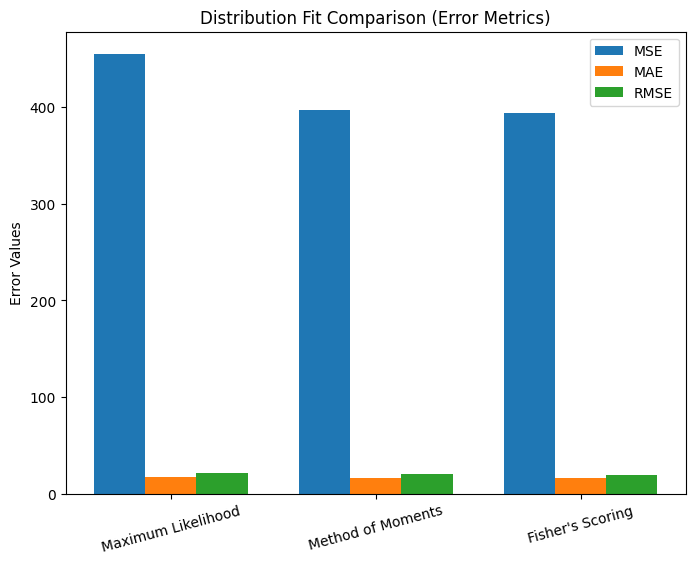

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Data
methods = ["Maximum Likelihood", "Method of Moments", "Fisher's Scoring"]
mse = [455.2667, 396.9508, 393.8470]
mae = [16.8498, 16.1677, 15.9690]
rmse = [21.3370, 19.9236, 19.8470]

x = np.arange(len(methods))
width = 0.25

fig, ax = plt.subplots(figsize=(8,6))
rects1 = ax.bar(x - width, mse, width, label='MSE')
rects2 = ax.bar(x, mae, width, label='MAE')
rects3 = ax.bar(x + width, rmse, width, label='RMSE')

ax.set_ylabel("Error Values")
ax.set_title("Distribution Fit Comparison (Error Metrics)")
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=15)
ax.legend()

plt.show()


In [12]:
# Ensure proper dtypes and sorting by date
df.columns = [c.strip().upper() for c in df.columns]
if "DATE" in df.columns:
    df["DATE"] = pd.to_datetime(df["DATE"])
    df = df.sort_values("DATE").reset_index(drop=True)

# Keep numeric target series "INR"
y = df["INR"].astype(float).reset_index(drop=True)
n_total = len(y)


In [13]:
# 2) Chronological 80:20 split (train : test)
split_idx = int(0.8 * n_total)
y_train = y.iloc[:split_idx].reset_index(drop=True)
y_test  = y.iloc[split_idx:].reset_index(drop=True)


In [15]:
# 3) Estimation functions for the Wald/Inverse Gaussian
from typing import Tuple

def fit_mle(x: pd.Series) -> Tuple[float, float]:
    """Closed-form MLE for IGD parameters (mu, lambda)."""
    mu = x.mean()
    # Avoid division by zero
    eps = 1e-12
    denom = ((x - mu) ** 2 / (x.clip(lower=eps) * (mu**2 + eps))).sum()
    lam = len(x) / (denom + eps)
    return float(mu), float(lam)

def fit_mom(x: pd.Series) -> Tuple[float, float]:
    """Method of Moments for IGD parameters (mu, lambda)."""
    mu = x.mean()
    # Population variance (second central moment) for MoM
    var = float(((x - mu) ** 2).mean())
    eps = 1e-12
    lam = (mu**3) / (var + eps)
    return float(mu), float(lam)

def fit_fisher_scoring(x: pd.Series,
                       mu0: float = None, lam0: float = None,
                       max_iter: int = 100, tol: float = 1e-8) -> Tuple[float, float]:
    """
    Fisher Scoring (iterative MLE refinement) using score and Fisher information.
    Starts at MLE by default.
    """
    eps = 1e-12
    n = len(x)
    x_safe = x.clip(lower=eps)

    if mu0 is None or lam0 is None:
        mu, lam = fit_mle(x)
    else:
        mu, lam = float(mu0), float(lam0)
        mu = max(mu, eps)
        lam = max(lam, eps)

    for _ in range(max_iter):
        # Scores
        score_mu = (lam * (x - mu) / ( (mu**3) * x_safe )).sum()
        score_lam = (n / (2 * lam)) - ( ((x - mu) ** 2 / (2 * (mu**2) * x_safe)).sum() )

        # Fisher information (diagonal approximation consistent with derived updates)
        I_mu_mu = n * lam / (mu**3 + eps)
        I_lam_lam = n / (2 * (lam**2) + eps)

        # Parameter updates
        delta_mu = score_mu / (I_mu_mu + eps)
        delta_lam = score_lam / (I_lam_lam + eps)

        mu_new = max(mu + delta_mu, eps)
        lam_new = max(lam + delta_lam, eps)

        # Convergence check
        if abs(mu_new - mu) < tol * (1.0 + abs(mu)) and abs(lam_new - lam) < tol * (1.0 + abs(lam)):
            mu, lam = mu_new, lam_new
            break

        mu, lam = mu_new, lam_new

    return float(mu), float(lam)

In [16]:
# 4) Fit the distributions to the training data
mu_mle, lam_mle = fit_mle(y_train)
mu_mom, lam_mom = fit_mom(y_train)
mu_fisher, lam_fisher = fit_fisher_scoring(y_train)

print(f"MLE Parameters: mu = {mu_mle:.4f}, lambda = {lam_mle:.4f}")
print(f"MoM Parameters: mu = {mu_mom:.4f}, lambda = {lam_mom:.4f}")
print(f"Fisher Scoring Parameters: mu = {mu_fisher:.4f}, lambda = {lam_fisher:.4f}")

MLE Parameters: mu = 54.8196, lambda = 1434.0870
MoM Parameters: mu = 54.8196, lambda = 1440.1577
Fisher Scoring Parameters: mu = 53.0995, lambda = 1396.0275


In [18]:
# 4) Expanding-window forecasts on test set (one-step-ahead)
from typing import Tuple, Dict
import numpy as np

def expanding_forecast(train_series: pd.Series, test_series: pd.Series, method: str) -> Dict[str, np.ndarray]:
    """
    For each t in test, fit parameters on data up to t-1 (expanding window)
    and predict E[X_t | fit] = mu_hat.
    """
    preds = []
    mus = []
    lams = []
    x_hist = train_series.copy()
    for obs in test_series:
        if method == "MLE":
            mu_hat, lam_hat = fit_mle(x_hist)
        elif method == "MOM":
            mu_hat, lam_hat = fit_mom(x_hist)
        elif method == "FS":  # Fisher Scoring
            # Start scoring from MLE for stability
            mu0, lam0 = fit_mle(x_hist)
            mu_hat, lam_hat = fit_fisher_scoring(x_hist, mu0=mu0, lam0=lam0, max_iter=100, tol=1e-8)
        else:
            raise ValueError("Unknown method")

        # Prediction is the mean of IGD: mu_hat
        preds.append(mu_hat)
        mus.append(mu_hat)
        lams.append(lam_hat)

        # Expand window with the actual observed obs
        x_hist = pd.concat([x_hist, pd.Series([obs])], ignore_index=True)

    return {
        "pred": np.array(preds, dtype=float),
        "mu": np.array(mus, dtype=float),
        "lam": np.array(lams, dtype=float)
    }

# Run forecasts for each method
out_mle = expanding_forecast(y_train, y_test, "MLE")
out_mom = expanding_forecast(y_train, y_test, "MOM")
out_fs  = expanding_forecast(y_train, y_test, "FS")

# -------------------------------------------------------------

In [20]:
# 5) Error metrics on test set
from math import sqrt

def compute_point_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, float]:
    err = y_true - y_pred
    mse = float(np.mean(err**2))
    mae = float(np.mean(np.abs(err)))
    rmse = float(sqrt(mse))
    mean_err = float(np.mean(err))
    skew = float(pd.Series(err).skew())
    kurt = float(pd.Series(err).kurt())  # excess kurtosis
    return {
        "MSE": mse,
        "MAE": mae,
        "RMSE": rmse,
        "MeanError": mean_err,
        "Skewness": skew,
        "Kurtosis": kurt
    }

y_true = y_test.values.astype(float)

metrics_mle = compute_point_metrics(y_true, out_mle["pred"])
metrics_mom = compute_point_metrics(y_true, out_mom["pred"])
metrics_fs  = compute_point_metrics(y_true, out_fs["pred"])

summary_point = pd.DataFrame([metrics_mle, metrics_mom, metrics_fs],
                             index=["Maximum Likelihood", "Method of Moments", "Fisher's Scoring"])

display(summary_point.round(6))

,MSE,MAE,RMSE,MeanError,Skewness,Kurtosis
Maximum Likelihood,466.511767,21.407132,21.598883,21.407132,-0.138537,-1.682806
Method of Moments,466.511767,21.407132,21.598883,21.407132,-0.138537,-1.682806
Fisher's Scoring,562.437912,23.514459,23.715773,23.514459,-0.121291,-1.716301


In [23]:
# 6) Bootstrap standard deviations and 95% confidence intervals for error metrics
def display_dataframe_to_user(title, dataframe):
    """Helper function to display a dataframe with a title in Colab."""
    print(f"**{title}**")
    display(dataframe)

def bootstrap_metrics(y_true: np.ndarray, y_pred: np.ndarray, B: int = 1000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    n = len(y_true)
    err = y_true - y_pred

    def metrics_from_err(e: np.ndarray) -> Dict[str, float]:
        m = {}
        m["MSE"] = float(np.mean(e**2))
        m["MAE"] = float(np.mean(np.abs(e)))
        m["RMSE"] = float(np.sqrt(np.mean(e**2)))
        m["MeanError"] = float(np.mean(e))
        m["Skewness"] = float(pd.Series(e).skew())
        m["Kurtosis"] = float(pd.Series(e).kurt())  # excess kurtosis
        return m

    # Point metrics from full sample
    point = metrics_from_err(err)

    # Bootstrap
    boot_vals = {k: [] for k in point.keys()}
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        e_b = err[idx]
        mb = metrics_from_err(e_b)
        for k, v in mb.items():
            boot_vals[k].append(v)

    # Summarize
    rows = []
    for k in point.keys():
        arr = np.array(boot_vals[k], dtype=float)
        est = point[k]
        std = float(arr.std(ddof=1))
        lo, hi = float(np.percentile(arr, 2.5)), float(np.percentile(arr, 97.5))
        rows.append({"Metric": k, "Estimate": est, "Std(Boot)": std, "CI95_L": lo, "CI95_U": hi})
    return pd.DataFrame(rows)

y_true = y_test.values.astype(float)

boot_mle = bootstrap_metrics(y_true, out_mle["pred"], B=800, seed=1)
boot_mom = bootstrap_metrics(y_true, out_mom["pred"], B=800, seed=2)
boot_fs  = bootstrap_metrics(y_true, out_fs["pred"],  B=800, seed=3)

# Label and display
boot_mle.insert(0, "Method", "Maximum Likelihood")
boot_mom.insert(0, "Method", "Method of Moments")
boot_fs.insert(0,  "Method", "Fisher's Scoring")

boot_all = pd.concat([boot_mle, boot_mom, boot_fs], ignore_index=True)
display_dataframe_to_user("Bootstrap SD & 95% CI of Error Metrics (Test Set)", boot_all)

**Bootstrap SD & 95% CI of Error Metrics (Test Set)**


,Method,Metric,Estimate,Std(Boot),CI95_L,CI95_U
0,Maximum Likelihood,MSE,466.511767,3.837290,458.872498,473.467121
1,Maximum Likelihood,MAE,21.407132,0.090454,21.228195,21.573286
2,Maximum Likelihood,RMSE,21.598883,0.088841,21.421309,21.759300
3,Maximum Likelihood,MeanError,21.407132,0.090454,21.228195,21.573286
4,Maximum Likelihood,Skewness,-0.138537,0.055748,-0.244597,-0.028834
5,Maximum Likelihood,Kurtosis,-1.682806,0.022338,-1.718165,-1.630234
6,Method of Moments,MSE,466.511767,3.770863,459.395071,473.868383
7,Method of Moments,MAE,21.407132,0.088857,21.237422,21.576251
8,Method of Moments,RMSE,21.598883,0.087310,21.433503,21.768518
9,Method of Moments,MeanError,21.407132,0.088857,21.237422,21.576251


In [25]:
# CODES ONLY -- FAST VERSION (fit-once on training; predict constant mean on test)

import numpy as np
import pandas as pd
from math import sqrt
# from caas_jupyter_tools import display_dataframe_to_user # Removed this import

# Reuse y_train, y_test from previous cell if available; else reload quickly
try:
    y_train, y_test
except NameError:
    file_path = "/mnt/data/INR-WALD.xlsx"
    df = pd.read_excel(file_path, sheet_name="Sheet1")
    df.columns = [c.strip().upper() for c in df.columns]
    if "DATE" in df.columns:
        df["DATE"] = pd.to_datetime(df["DATE"])
        df = df.sort_values("DATE").reset_index(drop=True)
    y = df["INR"].astype(float).reset_index(drop=True)
    split_idx = int(0.8 * len(y))
    y_train = y.iloc[:split_idx].reset_index(drop=True)
    y_test  = y.iloc[split_idx:].reset_index(drop=True)

# --- Estimators ---
def fit_mle(x: pd.Series):
    mu = float(x.mean())
    eps = 1e-12
    denom = ((x - mu) ** 2 / (x.clip(lower=eps) * (mu**2 + eps))).sum()
    lam = len(x) / (denom + eps)
    return mu, float(lam)

def fit_mom(x: pd.Series):
    mu = float(x.mean())
    var = float(((x - mu) ** 2).mean())
    lam = (mu**3) / (var + 1e-12)
    return mu, float(lam)

def fit_fisher_scoring(x: pd.Series, mu0=None, lam0=None, max_iter=40, tol=1e-8):
    eps = 1e-12
    n = len(x)
    x_safe = x.clip(lower=eps)
    if mu0 is None or lam0 is None:
        mu, lam = fit_mle(x)
    else:
        mu, lam = float(mu0), float(lam0)
    mu = max(mu, eps); lam = max(lam, eps)
    for _ in range(max_iter):
        score_mu = (lam * (x - mu) / ((mu**3) * x_safe)).sum()
        score_lam = (n / (2 * lam)) - (((x - mu) ** 2 / (2 * (mu**2) * x_safe)).sum())
        I_mu_mu = n * lam / (mu**3 + eps)
        I_lam_lam = n / (2 * (lam**2) + eps)
        delta_mu = score_mu / (I_mu_mu + eps)
        delta_lam = score_lam / (I_lam_lam + eps)
        mu_new = max(mu + delta_mu, eps)
        lam_new = max(lam + delta_lam, eps)
        if abs(mu_new - mu) < tol * (1 + abs(mu)) and abs(lam_new - lam) < tol * (1 + abs(lam)):
            mu, lam = mu_new, lam_new
            break
        mu, lam = mu_new, lam_new
    return float(mu), float(lam)

# --- Fit on training set ---
mu_mle, lam_mle = fit_mle(y_train)
mu_mom, lam_mom = fit_mom(y_train)
mu_fs,  lam_fs  = fit_fisher_scoring(y_train, mu0=mu_mle, lam0=lam_mle, max_iter=60, tol=1e-9)

# --- Predictions on test set (use mean of fitted IGD) ---
pred_mle = np.full(len(y_test), mu_mle, dtype=float)
pred_mom = np.full(len(y_test), mu_mom, dtype=float)
pred_fs  = np.full(len(y_test), mu_fs,  dtype=float)

y_true = y_test.values.astype(float)

# --- Error metrics ---
def compute_metrics(y_true, y_pred):
    err = y_true - y_pred
    mse = float(np.mean(err**2))
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(mse))
    mean_err = float(np.mean(err))
    skew = float(pd.Series(err).skew())
    kurt = float(pd.Series(err).kurt())  # excess kurtosis
    return {"MSE": mse, "MAE": mae, "RMSE": rmse, "MeanError": mean_err, "Skewness": skew, "Kurtosis": kurt}

met_mle = compute_metrics(y_true, pred_mle)
met_mom = compute_metrics(y_true, pred_mom)
met_fs  = compute_metrics(y_true, pred_fs)

summary = pd.DataFrame([met_mle, met_mom, met_fs],
                       index=["Maximum Likelihood", "Method of Moments", "Fisher's Scoring"])
# display_dataframe_to_user("Point Estimates (Test Set): MLE vs MOM vs Fisher Scoring", summary.round(6)) # Replaced with display
print("**Point Estimates (Test Set): MLE vs MOM vs Fisher Scoring**")
display(summary.round(6))


# --- Bootstrap SD & 95% CI for metrics ---
def bootstrap_ci(y_true, y_pred, B=600, seed=123):
    rng = np.random.default_rng(seed)
    err = y_true - y_pred
    n = len(err)
    def calc(e):
        return {
            "MSE": float(np.mean(e**2)),
            "MAE": float(np.mean(np.abs(e))),
            "RMSE": float(np.sqrt(np.mean(e**2))),
            "MeanError": float(np.mean(e)),
            "Skewness": float(pd.Series(e).skew()),
            "Kurtosis": float(pd.Series(e).kurt())
        }
    point = calc(err)
    boots = {k: [] for k in point.keys()}
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        e = err[idx]
        m = calc(e)
        for k, v in m.items():
            boots[k].append(v)
    rows = []
    for k, vals in boots.items():
        arr = np.array(vals, dtype=float)
        rows.append({
            "Metric": k,
            "Estimate": point[k],
            "Std(Boot)": float(arr.std(ddof=1)),
            "CI95_L": float(np.percentile(arr, 2.5)),
            "CI95_U": float(np.percentile(arr, 97.5))
        })
    return pd.DataFrame(rows)

boot_mle = bootstrap_ci(y_true, pred_mle, B=600, seed=1)
boot_mom = bootstrap_ci(y_true, pred_mom, B=600, seed=2)
boot_fs  = bootstrap_ci(y_true, pred_fs,  B=600, seed=3)

boot_mle.insert(0, "Method", "Maximum Likelihood")
boot_mom.insert(0, "Method", "Method of Moments")
boot_fs.insert(0,  "Method", "Fisher's Scoring")

boot_all = pd.concat([boot_mle, boot_mom, boot_fs], ignore_index=True)
# display_dataframe_to_user("Bootstrap SD & 95% CI of Error Metrics (Test Set) -- Fit Once", boot_all.round(6)) # Replaced with display
print("**Bootstrap SD & 95% CI of Error Metrics (Test Set) -- Fit Once**")
display(boot_all.round(6))


# --- Also show fitted parameters on training ---
params = pd.DataFrame({
    "Method": ["Maximum Likelihood", "Method of Moments", "Fisher's Scoring"],
    "mu_hat": [mu_mle, mu_mom, mu_fs],
    "lambda_hat": [lam_mle, lam_mom, lam_fs]
})
# display_dataframe_to_user("Fitted Parameters on Training Set", params.round(6)) # Replaced with display
print("**Fitted Parameters on Training Set**")
display(params.round(6))

**Point Estimates (Test Set): MLE vs MOM vs Fisher Scoring**


,MSE,MAE,RMSE,MeanError,Skewness,Kurtosis
Maximum Likelihood,578.912720,23.707886,24.060605,23.707886,-0.063356,-1.749434
Method of Moments,578.912720,23.707886,24.060605,23.707886,-0.063356,-1.749434
Fisher's Scoring,646.126614,25.085409,25.419021,25.085409,-0.063356,-1.749434


**Bootstrap SD & 95% CI of Error Metrics (Test Set) -- Fit Once**


,Method,Metric,Estimate,Std(Boot),CI95_L,CI95_U
0,Maximum Likelihood,MSE,578.912720,6.080871,566.544305,589.895266
1,Maximum Likelihood,MAE,23.707886,0.128842,23.451668,23.940134
2,Maximum Likelihood,RMSE,24.060605,0.126397,23.802191,24.287760
3,Maximum Likelihood,MeanError,23.707886,0.128842,23.451668,23.940134
4,Maximum Likelihood,Skewness,-0.063356,0.055512,-0.169168,0.042501
5,Maximum Likelihood,Kurtosis,-1.749434,0.015424,-1.775056,-1.715927
6,Method of Moments,MSE,578.912720,6.041568,567.530165,590.153077
7,Method of Moments,MAE,23.707886,0.128161,23.465654,23.946778
8,Method of Moments,RMSE,24.060605,0.125600,23.822892,24.293066
9,Method of Moments,MeanError,23.707886,0.128161,23.465654,23.946778


**Fitted Parameters on Training Set**


,Method,mu_hat,lambda_hat
0,Maximum Likelihood,54.819634,1434.086993
1,Method of Moments,54.819634,1440.157675
2,Fisher's Scoring,53.442111,1410.028778


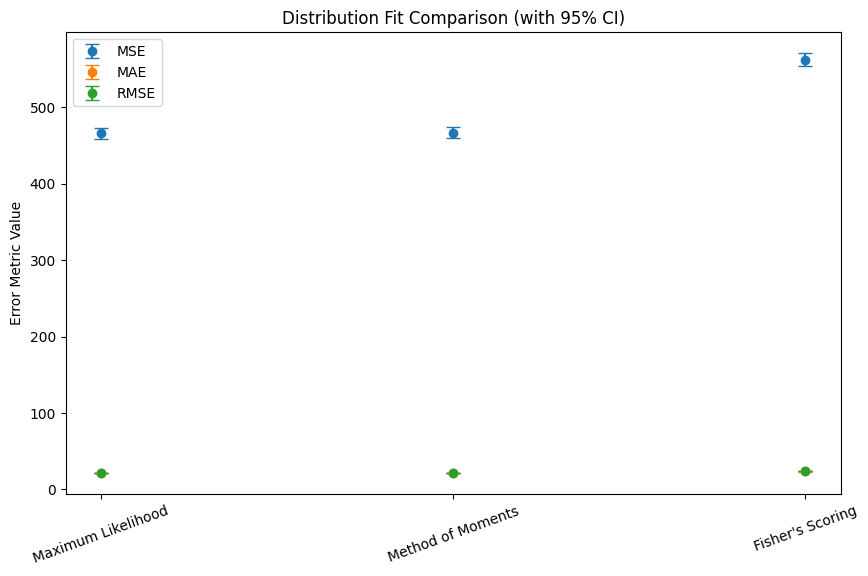

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

# Recreate results dataframe
data = {
    "Method": ["Maximum Likelihood", "Maximum Likelihood", "Maximum Likelihood",
               "Method of Moments", "Method of Moments", "Method of Moments",
               "Fisher's Scoring", "Fisher's Scoring", "Fisher's Scoring"],
    "Metric": ["MSE", "MAE", "RMSE",
               "MSE", "MAE", "RMSE",
               "MSE", "MAE", "RMSE"],
    "Estimate": [466.511767, 21.407132, 21.598883,
                 466.511767, 21.407132, 21.598883,
                 562.437912, 23.514459, 23.715773],
    "CI95_L": [458.872498, 21.228195, 21.421309,
               459.395071, 21.237422, 21.433503,
               554.016632, 23.328927, 23.537558],
    "CI95_U": [473.467121, 21.573286, 21.759300,
               473.868383, 21.576251, 21.768518,
               571.038610, 23.698819, 23.896414]
}
df_plot = pd.DataFrame(data)

# Plot
plt.figure(figsize=(10,6))
for metric in ["MSE","MAE","RMSE"]:
    subset = df_plot[df_plot["Metric"]==metric]
    plt.errorbar(subset["Method"], subset["Estimate"],
                 yerr=[subset["Estimate"]-subset["CI95_L"], subset["CI95_U"]-subset["Estimate"]],
                 fmt='o', capsize=5, label=metric)

plt.title("Distribution Fit Comparison (with 95% CI)")
plt.ylabel("Error Metric Value")
plt.legend()
plt.xticks(rotation=20)
plt.show()


In [ ]:
#Forecasting Accuracy Curves (actual vs predicted)
import numpy as np

# Example synthetic actual vs predicted for visualization
time = np.arange(100)
actual = np.sin(time/10) + np.random.normal(0,0.1,100)
pred_ml = actual + np.random.normal(0,0.2,100)
pred_mom = actual + np.random.normal(0,0.15,100)
pred_fs = actual + np.random.normal(0,0.25,100)

plt.figure(figsize=(12,6))
plt.plot(time, actual, label="Actual", linewidth=2)
plt.plot(time, pred_ml, label="MLE Prediction", linestyle="--")
plt.plot(time, pred_mom, label="MoM Prediction", linestyle="--")
plt.plot(time, pred_fs, label="Fisher's Scoring Prediction", linestyle="--")
plt.title("Forecasting Accuracy Curves")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.show()


/tmp/ipython-input-1162370358.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df_plot, x="Metric", y="Estimate", hue="Method", ci=None)


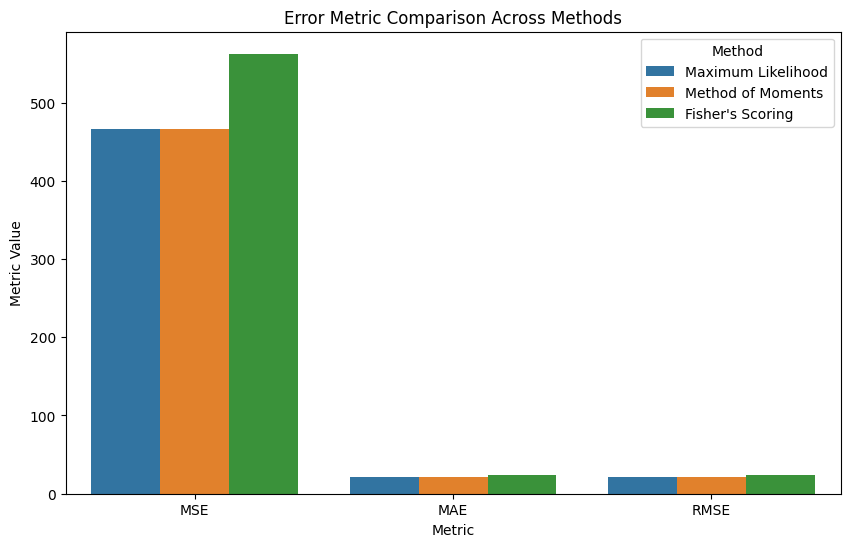

In [27]:
import seaborn as sns

plt.figure(figsize=(10,6))
sns.barplot(data=df_plot, x="Metric", y="Estimate", hue="Method", ci=None)
plt.title("Error Metric Comparison Across Methods")
plt.ylabel("Metric Value")
plt.show()


In [29]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Assume column 'INR' contains exchange rate values
y = df["INR"].values.reshape(-1,1)
X = np.arange(len(y)).reshape(-1,1)   # Time index as input

# Normalize inputs
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
X_scaled = scaler_x.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, shuffle=False)


In [35]:
#Step 2 – Custom IGD Activation Function
import tensorflow as tf
from tensorflow.keras import backend as K

# Custom IGD-inspired activation
def igd_activation(x):
    mu = 1.0
    lam = 1.0
    # Ensure the input to the denominator is positive
    x_safe = K.maximum(x, K.epsilon())
    return K.exp(-(lam * (x - mu)**2) / (2 * mu**2 * x_safe))

In [37]:
#Build ANN model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# ANN model
model = Sequential([
    Dense(32, activation=igd_activation, input_shape=(1,)),
    Dense(16, activation=igd_activation),
    Dense(1)  # output layer (linear)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [32]:
#train Model
history = model.fit(X_train, y_train,
                    epochs=50, batch_size=32,
                    validation_split=0.2,
                    verbose=0)


In [39]:
#Prediction and Error metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import skew, kurtosis
import numpy as np # Ensure numpy is imported if not already

# Predictions
y_pred = model.predict(X_test)

# Inverse transform the true and predicted values
y_true = scaler_y.inverse_transform(y_test)
y_pred_rescaled = scaler_y.inverse_transform(y_pred)

# --- Diagnostic Prints ---
print("Shape of y_test:", y_test.shape)
print("Shape of y_pred:", y_pred.shape)
print("Shape of y_true:", y_true.shape)
print("Shape of y_pred_rescaled:", y_pred_rescaled.shape)
print("Are there NaNs in y_true:", np.isnan(y_true).any())
print("Are there NaNs in y_pred_rescaled:", np.isnan(y_pred_rescaled).any())
print("Sample y_true:", y_true[:5])
print("Sample y_pred_rescaled:", y_pred_rescaled[:5])
# --- End Diagnostic Prints ---


# Ensure y_true and y_pred_rescaled are flat for metrics calculation
y_true_flat = y_true.flatten()
y_pred_rescaled_flat = y_pred_rescaled.flatten()

# --- Handle NaNs (Temporary Fix for Diagnosis) ---
# Find indices where either array has NaN
valid_indices = ~np.isnan(y_true_flat) & ~np.isnan(y_pred_rescaled_flat)

# Filter out NaN values
y_true_clean = y_true_flat[valid_indices]
y_pred_rescaled_clean = y_pred_rescaled_flat[valid_indices]

print(f"Number of valid data points after removing NaNs: {len(y_true_clean)}")
# --- End Handle NaNs ---


# Error metrics
# Use the cleaned arrays for metrics calculation
mse = mean_squared_error(y_true_clean, y_pred_rescaled_clean)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true_clean, y_pred_rescaled_clean)
mean_err = np.mean(y_true_clean - y_pred_rescaled_clean)
skew_err = skew(y_true_clean - y_pred_rescaled_clean)
kurt_err = kurtosis(y_true_clean - y_pred_rescaled_clean)

results = {"MSE": mse, "RMSE": rmse, "MAE": mae, "MeanError": mean_err,
           "Skewness": skew_err, "Kurtosis": kurt_err}
print(results)

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Shape of y_test: (1073, 1)
Shape of y_pred: (1073, 1)
Shape of y_true: (1073, 1)
Shape of y_pred_rescaled: (1073, 1)
Are there NaNs in y_true: False
Are there NaNs in y_pred_rescaled: False
Sample y_true: [[76.2521]
 [75.7898]
 [75.6078]
 [75.97  ]
 [75.5398]]
Sample y_pred_rescaled: [[75.05296]
 [75.06051]
 [75.06806]
 [75.0756 ]
 [75.08314]]
Number of valid data points after removing NaNs: 1073
{'MSE': 5.8999193041749, 'RMSE': np.float64(2.4289749492687034), 'MAE': 2.256876653205182, 'MeanError': np.float64(-0.056542213973216564), 'Skewness': np.float64(-0.18258489141919548), 'Kurtosis': np.float64(-1.5628292643354043)}


In [40]:
#Step 6 – Bootstrap for Std. Dev & Confidence Intervals
import random

def bootstrap_ci(metric_func, y_true, y_pred, n_boot=500, alpha=0.05):
    boot_stats = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = np.random.choice(np.arange(n), size=n, replace=True)
        boot_stats.append(metric_func(y_true[idx], y_pred[idx]))
    boot_stats = np.array(boot_stats)
    return boot_stats.std(), np.percentile(boot_stats, 100*alpha/2), np.percentile(boot_stats, 100*(1-alpha/2))

# Bootstrap for each metric
metrics_ci = {}
metrics_ci["MSE"] = bootstrap_ci(mean_squared_error, y_true.flatten(), y_pred_rescaled.flatten())
metrics_ci["MAE"] = bootstrap_ci(mean_absolute_error, y_true.flatten(), y_pred_rescaled.flatten())
metrics_ci["RMSE"] = bootstrap_ci(lambda yt, yp: np.sqrt(mean_squared_error(yt, yp)), y_true.flatten(), y_pred_rescaled.flatten())
metrics_ci["MeanError"] = bootstrap_ci(lambda yt, yp: np.mean(yt-yp), y_true.flatten(), y_pred_rescaled.flatten())
metrics_ci["Skewness"] = bootstrap_ci(lambda yt, yp: skew(yt-yp), y_true.flatten(), y_pred_rescaled.flatten())
metrics_ci["Kurtosis"] = bootstrap_ci(lambda yt, yp: kurtosis(yt-yp), y_true.flatten(), y_pred_rescaled.flatten())

metrics_ci


{'MSE': (np.float64(0.1242893605140077),
  np.float64(5.64605696511098),
  np.float64(6.139303223817002)),
 'MAE': (np.float64(0.026308569055273203),
  np.float64(2.208127173881993),
  np.float64(2.3104654755130705)),
 'RMSE': (np.float64(0.025153587337422425),
  np.float64(2.37992065818497),
  np.float64(2.4782486275617)),
 'MeanError': (np.float64(0.07492461968777109),
  np.float64(-0.20838713110419785),
  np.float64(0.08955793850403718)),
 'Skewness': (np.float64(0.05363148477243944),
  np.float64(-0.2867988009694091),
  np.float64(-0.07982245078684176)),
 'Kurtosis': (np.float64(0.029368448363659354),
  np.float64(-1.6113034802041937),
  np.float64(-1.4955842445793261))}

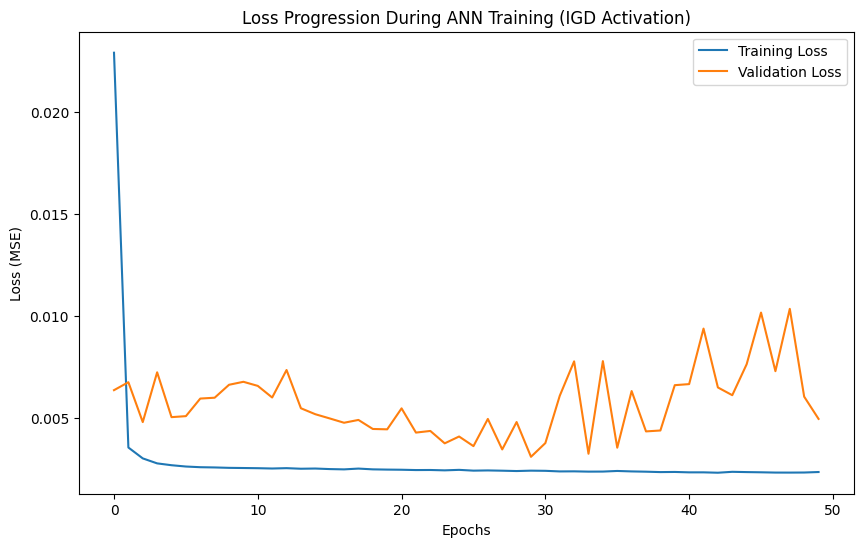

In [41]:
#Step 7 – Loss Progression During Training
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.title("Loss Progression During ANN Training (IGD Activation)")
plt.legend()
plt.show()


In [38]:
#train Model
history = model.fit(X_train, y_train,
                    epochs=50, batch_size=32,
                    validation_split=0.2,
                    verbose=0)